# Лабораторная работа №5. Работа с файлами в Linux средствами ассемблера

**Студент:** Сорокин Никита Васильевич  
**Вариант:** 19 (Задание 11 и 1)  

---  

## Задание 11
**Условие:**  
Для заданного $n$ записать в файл все простые числа от 1 до $n$. После этого оставить только простые числа, заканчивающиеся на единицу. Имена файлов и значение $n$ передаются через аргументы командной строки.

---  

## Задание 1
**Условие:**  
Для заданного текстового файла (латиница) производится подсчет количества букв, цифр. Результат подсчета записать во второй файл в формате:
* `number of letters:...`
* `number of digits:...`


## Реализация Задания №11 (`task11.asm`)

In [ ]:
format ELF executable 3
entry start

segment readable executable

start:
    pop eax
    cmp eax, 3
    jl exit_err

    pop eax
    pop ebx
    pop ecx

    mov [file_out], ebx

    mov esi, ecx
    xor eax, eax
conv_loop:
    movzx edx, byte [esi]
    cmp edx, 0
    je conv_done
    sub edx, '0'
    imul eax, eax, 10
    add eax, edx
    inc esi
    jmp conv_loop
conv_done:
    mov [n_val], eax

    mov eax, 8
    mov ebx, [file_out]
    mov ecx, 438
    int 0x80
    cmp eax, 0
    jl exit_err
    mov [fd_out], eax

    mov ecx, 2
check_prime_loop:
    cmp ecx, [n_val]
    jg finish_gen

    mov edi, 2
prime_subloop:
    cmp edi, ecx
    jge is_prime
    mov eax, ecx
    xor edx, edx
    mov ebx, edi
    div ebx
    cmp edx, 0
    je not_prime
    inc edi
    jmp prime_subloop

is_prime:
    mov eax, ecx
    xor edx, edx
    mov ebx, 10
    div ebx
    cmp edx, 1
    jne not_prime

    call int_to_str

    push ecx
    mov eax, 4
    mov ebx, [fd_out]
    mov ecx, num_str
    mov edx, [str_len]
    int 0x80

    mov eax, 4
    mov ebx, [fd_out]
    mov ecx, newline
    mov edx, 1
    int 0x80
    pop ecx

not_prime:
    inc ecx
    jmp check_prime_loop

finish_gen:
    mov eax, 6
    mov ebx, [fd_out]
    int 0x80

    mov eax, 1
    mov ebx, 0
    int 0x80

exit_err:
    mov eax, 1
    mov ebx, 1
    int 0x80

int_to_str:
    push eax
    push ebx
    push ecx
    push edx
    push esi

    mov eax, ecx
    mov edi, num_str + 10
    mov byte [edi], 0
    mov ecx, 10
    mov [str_len], 0

itoa_loop:
    xor edx, edx
    div ecx
    add dl, '0'
    dec edi
    mov byte [edi], dl
    inc dword [str_len]
    cmp eax, 0
    jne itoa_loop

    mov esi, edi
    mov edi, num_str
    mov ecx, [str_len]
    cld
    rep movsb

    pop esi
    pop edx
    pop ecx
    pop ebx
    pop eax
    ret

segment readable writeable
    file_out   dd 0
    fd_out     dd 0
    n_val      dd 0
    str_len    dd 0
    newline    db 0x0A
    num_str    rb 20


## Реализация Задания №1 (`task1.asm`)

In [ ]:
format ELF executable 3
entry start

segment readable executable

start:
    pop eax             ; argc
    cmp eax, 3
    jl exit_err

    pop eax
    pop ebx             ; argv[1] - input file
    pop ecx             ; argv[2] - output file

    mov [file_in], ebx
    mov [file_out], ecx

    mov eax, 5
    mov ebx, [file_in]
    mov ecx, 0
    mov edx, 0
    int 0x80
    cmp eax, 0
    jl exit_err
    mov [fd_in], eax

    mov eax, 3
    mov ebx, [fd_in]
    mov ecx, buffer
    mov edx, 10000
    int 0x80
    mov [buf_len], eax

    mov eax, 6
    mov ebx, [fd_in]
    int 0x80

    mov esi, buffer
    mov ecx, [buf_len]
    xor ebx, ebx
    xor edx, edx

count_loop:
    cmp ecx, 0
    jle save_result
    mov al, byte [esi]

    cmp al, '0'
    jl check_letter
    cmp al, '9'
    jg check_letter
    inc edx
    jmp next_sym

check_letter:
    cmp al, 'A'
    jl check_low
    cmp al, 'Z'
    jle is_let

check_low:
    cmp al, 'a'
    jl next_sym
    cmp al, 'z'
    jg next_sym

is_let:
    inc ebx

next_sym:
    inc esi
    dec ecx
    jmp count_loop

save_result:
    mov [letters_cnt], ebx
    mov [digits_cnt], edx

    mov eax, 8
    mov ebx, [file_out]
    mov ecx, 438
    int 0x80
    cmp eax, 0
    jl exit_err
    mov [fd_out], eax

    mov eax, 4
    mov ebx, [fd_out]
    mov ecx, msg_letters
    mov edx, 18
    int 0x80

    mov ecx, [letters_cnt]
    call int_to_str
    mov eax, 4
    mov ebx, [fd_out]
    mov ecx, num_str
    mov edx, [str_len]
    int 0x80

    mov eax, 4
    mov ebx, [fd_out]
    mov ecx, newline
    mov edx, 1
    int 0x80

    mov eax, 4
    mov ebx, [fd_out]
    mov ecx, msg_digits
    mov edx, 17
    int 0x80

    mov ecx, [digits_cnt]
    call int_to_str
    mov eax, 4
    mov ebx, [fd_out]
    mov ecx, num_str
    mov edx, [str_len]
    int 0x80

    mov eax, 4
    mov ebx, [fd_out]
    mov ecx, newline
    mov edx, 1
    int 0x80

    mov eax, 6
    mov ebx, [fd_out]
    int 0x80

    mov eax, 1
    mov ebx, 0
    int 0x80

exit_err:
    mov eax, 1
    mov ebx, 1
    int 0x80

int_to_str:
    push eax
    push ebx
    push ecx
    push edx
    push esi
    mov eax, ecx
    mov edi, num_str + 10
    mov byte [edi], 0
    mov ecx, 10
    mov [str_len], 0
itoa_loop:
    xor edx, edx
    div ecx
    add dl, '0'
    dec edi
    mov byte [edi], dl
    inc dword [str_len]
    cmp eax, 0
    jne itoa_loop
    mov esi, edi
    mov edi, num_str
    mov ecx, [str_len]
    cld
    rep movsb
    pop esi
    pop edx
    pop ecx
    pop ebx
    pop eax
    ret

segment readable writeable
    file_in     dd 0
    file_out    dd 0
    fd_in       dd 0
    fd_out      dd 0
    buf_len     dd 0
    letters_cnt dd 0
    digits_cnt  dd 0
    msg_letters db "number of letters:"
    msg_digits  db "number of digits:"
    newline     db 0x0A
    str_len     dd 0
    num_str     rb 20
    buffer      rb 10000


## Компиляция

![Снимок экрана 2026-10-23 085857.png](<attachment:Снимок экрана 2026-10-23 085857.png>)
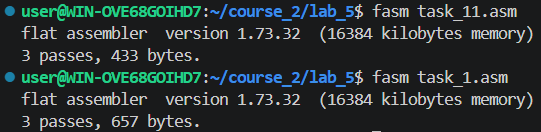

## Ввод данных и запуск
Для задания 1 создаем файл input1.txt с фразой "Hello 123 World 456"

![Снимок экрана 2026-10-23 090537.png](<attachment:Снимок экрана 2026-10-23 090537.png>)
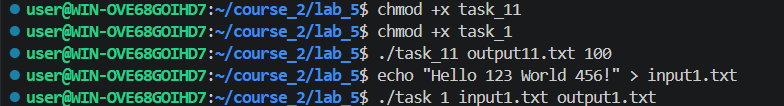

## Проверяем результаты

![Снимок экрана 2026-10-23 090614.png](<attachment:Снимок экрана 2026-10-23 090614.png>)
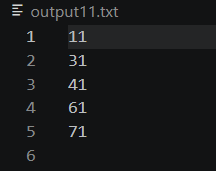

![Снимок экрана 2026-10-23 090624.png](<attachment:Снимок экрана 2026-10-23 090624.png>)
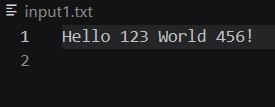

![Снимок экрана 2026-10-23 090636.png](<attachment:Снимок экрана 2026-10-23 090636.png>)
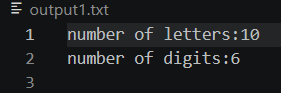